# IS630: Green Light for an Indie Studio
## Notebook 01: Exploratory Data Analysis
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All code blocks below are labeled as AI-assisted. All modelling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below.

This notebook works through one data question per section, building towards **AQ1: what is a good metric for evaluating a game's success?**

| Section | Question |
|---|---|
| 1 | What does our data look like, and how are the variables distributed? |
| 2 | Where is data missing, and what anomalies does the data contain? |
| 3 | What are the prospective target variables, and which one makes sense? |
| 4 | What do the top games look like on each prospective metric? |
| 5 | What bias did the merge introduce, and is the matched set representative? |
| 6 | How does game age affect reception? |
| 7 | How do the variables correlate? |
| 8 | *Suggested*: how much evidence sits behind each estimate? |

Every column carries its source as a prefix. `steam_` comes from the Steam dataset and `hltb_` from HowLongToBeat. Four columns describe the join itself or combine both sources, so they carry no prefix: `title_key`, `matched_hltb`, `year_diff` and `completion_ratio`.

Where a variable is plotted on a log scale, the untransformed version is shown beside it.

**Reads:** `data/interim/00_train.parquet`
**Writes:** `data/interim/01_eda.parquet`, figures to `outputs/figures`

The held-out test set is never loaded here. Every figure and statistic below describes the training set only.

## Setup
*Code: Generated by AI Assistant*

*Written by AI Assistant*: `raw_vs_log` plots any heavy-tailed variable twice, untransformed and then on a log-scaled axis, so the transformation never hides what the original looked like. The raw panel is clipped at a stated percentile, otherwise a few extreme values compress everything else into the first bin.

In [1]:
# Reload src/is630 whenever it changes. Without this, a kernel left running keeps
# the first version of each module it imported, and edits to features.py or
# config.py are silently ignored until the kernel restarts.
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except NameError:
    pass  # not running under IPython

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()) / "src"))
from is630 import config
from is630.features import add_derived

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 10.5
plt.rcParams["axes.labelsize"] = 9.5
pd.set_option("display.width", 200)

config.FIGURES.mkdir(parents=True, exist_ok=True)
for stale in config.FIGURES.glob("01_*.png"):
    stale.unlink()  # clear this notebook's figures so outputs match the current run

def save_fig(fig, name):
    """Write a figure to outputs/figures at 300 dpi."""
    fig.savefig(config.FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

def ascii_names(s):
    """Strip non-ASCII title characters so tables print cleanly in any console."""
    return s.astype(str).str.encode("ascii", "replace").str.decode("ascii")

# Plain-number tick labels for log axes: 1, 10, 100, 1,000 rather than 10^0, 10^1.
READABLE = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}")

def raw_vs_log(axes_pair, series, label, colour="steelblue", clip_q=0.99, drop_zero=True):
    """Plot a variable untransformed on the left and on a log-scaled axis on the right.

    The raw panel is clipped at a high percentile, otherwise a handful of extreme
    values compress everything else into the first bin. The clip point is stated
    in the title. Zeros are dropped from the log panel because zero cannot sit on a
    log axis, and the count dropped is stated."""
    ax_raw, ax_log = axes_pair
    s = series.dropna()

    cut = s.quantile(clip_q)
    shown = s[s <= cut]
    ax_raw.hist(shown, bins=50, color=colour, edgecolor="black", alpha=0.85)
    ax_raw.set_title(f"{label}\nraw, clipped at p{int(clip_q * 100)} = {cut:,.2f}")
    ax_raw.set_xlabel(label)
    ax_raw.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if abs(v) >= 1 or v == 0 else f"{v:g}"))

    pos = s[s > 0] if drop_zero else s
    n_zero = int((s <= 0).sum())
    # Log-spaced bins on a log axis: the same shape as a histogram of log10 values,
    # but the tick labels show the real values rather than exponents.
    bins = np.logspace(np.log10(pos.min()), np.log10(pos.max()), 51)
    ax_log.hist(pos, bins=bins, color=colour, edgecolor="black", alpha=0.85)
    ax_log.set_xscale("log")
    ax_log.xaxis.set_major_formatter(READABLE)
    ax_log.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax_log.set_title(f"{label}\nlog axis, {n_zero:,} non-positive dropped")
    ax_log.set_xlabel(f"{label} (log axis)")

In [2]:
train = pd.read_parquet(config.INTERIM / "00_train.parquet")
print(f"rows in: {len(train):,}")

df = add_derived(train)
matched = df[df["matched_hltb"]].copy()
print(f"matched to HowLongToBeat: {len(matched):,} ({len(matched) / len(df) * 100:.1f}%)")
print(f"columns: {train.shape[1]} in, {df.shape[1]} after derived columns")

rows in: 97,026
matched to HowLongToBeat: 16,660 (17.2%)
columns: 72 in, 81 after derived columns


## 1. What does our data look like?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: columns are grouped by what they describe rather than listed in file order. The source prefix is what separates the two datasets' name, date, genre and hour columns.

In [3]:
# What the columns are, grouped by what they describe
groups = {
    "Identity": ["steam_appid", "steam_name", "steam_release_date", "steam_year", "steam_years_since_release"],
    "Reception": ["steam_positive", "steam_negative", "steam_review_count", "steam_positive_rate",
                  "steam_metacritic_score", "steam_user_score", "steam_recommendations"],
    "Engagement": ["steam_median_playtime_forever", "steam_playtime_hours", "steam_average_playtime_forever",
                   "steam_peak_ccu", "steam_estimated_owners", "steam_owners_lower", "steam_owners_upper"],
    "Controllable": ["steam_price", "steam_achievements", "steam_dlc_count", "steam_language_count",
                     "steam_required_age", "steam_genres", "steam_categories", "steam_tags"],
    "HowLongToBeat": ["hltb_main_story", "hltb_main_story_polled", "hltb_main_plus_sides", "hltb_completionist"],
    "Join": ["title_key", "matched_hltb", "year_diff", "completion_ratio"],
}
rows = []
for group, cols in groups.items():
    for col in cols:
        if col in df.columns:
            rows.append({"group": group, "column": col, "dtype": str(df[col].dtype),
                         "n_unique": df[col].nunique(), "pct_null": round(df[col].isna().mean() * 100, 1)})
schema = pd.DataFrame(rows)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns\n")
schema

97,026 rows x 81 columns



,group,column,dtype,n_unique,pct_null
0,Identity,steam_appid,int64,97026,0.0
1,Identity,steam_name,object,97026,0.0
2,Identity,steam_release_date,object,4996,0.0
3,Identity,steam_year,int32,30,0.0
4,Identity,steam_years_since_release,int32,30,0.0
5,Reception,steam_positive,int64,4754,0.0
6,Reception,steam_negative,int64,2347,0.0
7,Reception,steam_review_count,int64,5068,0.0
8,Reception,steam_positive_rate,float64,14764,33.5
9,Reception,steam_metacritic_score,int64,72,0.0


**Author**: Lee Sin Yang

The data can be split into 6 main types of fields. HLTB adds additional reception / engagement metrics that we will evaluate. Most of the columns from the steam dataset have little null values, but the HLTB fields have high null rates due to the matching criteria described in the previous notebook.

In [4]:
cols = ["steam_price", "steam_achievements", "steam_dlc_count", "steam_language_count",
        "steam_required_age", "steam_years_since_release", "steam_review_count",
        "steam_playtime_hours", "hltb_main_story"]
desc = df[cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["skew"] = df[cols].skew()
desc["pct_zero"] = (df[cols] == 0).mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew,pct_zero
steam_price,97026.0,4.87,12.92,0.00,0.59,2.39,5.59,14.99,29.99,999.98,23.37,20.73
steam_achievements,97026.0,18.50,146.40,0.00,0.00,3.00,19.00,55.00,100.00,9821.00,32.14,47.76
steam_dlc_count,97026.0,0.53,15.22,0.00,0.00,0.00,0.00,2.00,6.00,3703.00,181.34,85.45
steam_language_count,97026.0,5.33,13.64,0.00,1.00,1.00,5.00,16.00,103.00,103.00,6.07,6.48
steam_required_age,97026.0,0.16,1.64,0.00,0.00,0.00,0.00,0.00,10.00,21.00,9.98,98.98
steam_years_since_release,97026.0,4.39,3.32,0.00,2.00,4.00,6.00,10.00,14.00,29.00,1.05,2.57
steam_review_count,97026.0,1205.18,34846.33,0.00,0.00,7.00,48.00,1312.00,15179.50,8815087.00,178.37,33.47
steam_playtime_hours,97026.0,2.77,187.89,0.00,0.00,0.00,0.00,6.71,26.25,57159.07,291.03,78.70
hltb_main_story,16660.0,7.42,20.31,0.01,1.33,3.50,8.10,26.27,53.01,1591.65,40.31,0.00


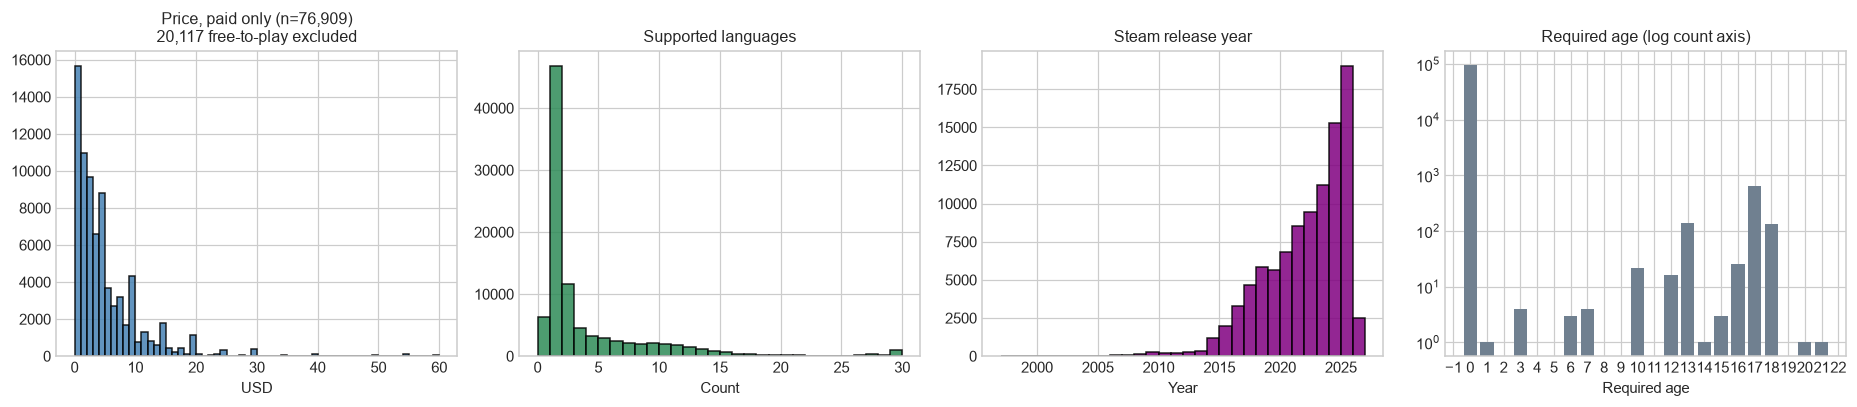

In [5]:
from matplotlib.ticker import MultipleLocator
# Variables that need no transformation
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))

paid = df.loc[df["steam_price"] > 0, "steam_price"]
axes[0].hist(paid, bins=60, range=(0, 60), color="steelblue", edgecolor="black", alpha=0.85)
axes[0].set_title(f"Price, paid only (n={len(paid):,})\n{(df['steam_price'] == 0).sum():,} free-to-play excluded")
axes[0].set_xlabel("USD")

axes[1].hist(df["steam_language_count"], bins=range(0, 31), color="seagreen", edgecolor="black", alpha=0.85)
axes[1].set_title("Supported languages")
axes[1].set_xlabel("Count")

yrs = df["steam_year"].dropna()
axes[2].hist(yrs, bins=range(int(yrs.min()), int(yrs.max()) + 2), color="purple", edgecolor="black", alpha=0.85)
axes[2].set_title("Steam release year")
axes[2].set_xlabel("Year")

age = df["steam_required_age"].value_counts().sort_index()
axes[3].bar(age.index, age.values, color="slategray")
axes[3].xaxis.set_major_locator(MultipleLocator(1))
axes[3].set_yscale("log")
axes[3].set_title("Required age (log count axis)")
axes[3].set_xlabel("Required age")

plt.tight_layout()
save_fig(fig, "01_q1_variables_untransformed")
plt.show()

**Author**: Lee Sin Yang

Price for paid games follows a downward trend, with a long right tail of games > $20. This indicates that the majority of paid games released are targeted fairly affordably, though this does not mean it has good total revenue.

Supported languages peaks at 1, with a long right tail up to 30. Most games are made in and targeting one main language.

The number of games has been increasing year over year, with noticeable increases in 2024 and 2025 over the previous years. The data stopped partly through 2026, hence the small bar. 

Age requirement for games varies, but generally clusters around regulatory requirements. Key numbers are 17/18 for adult games and 13 for semi-violent games.

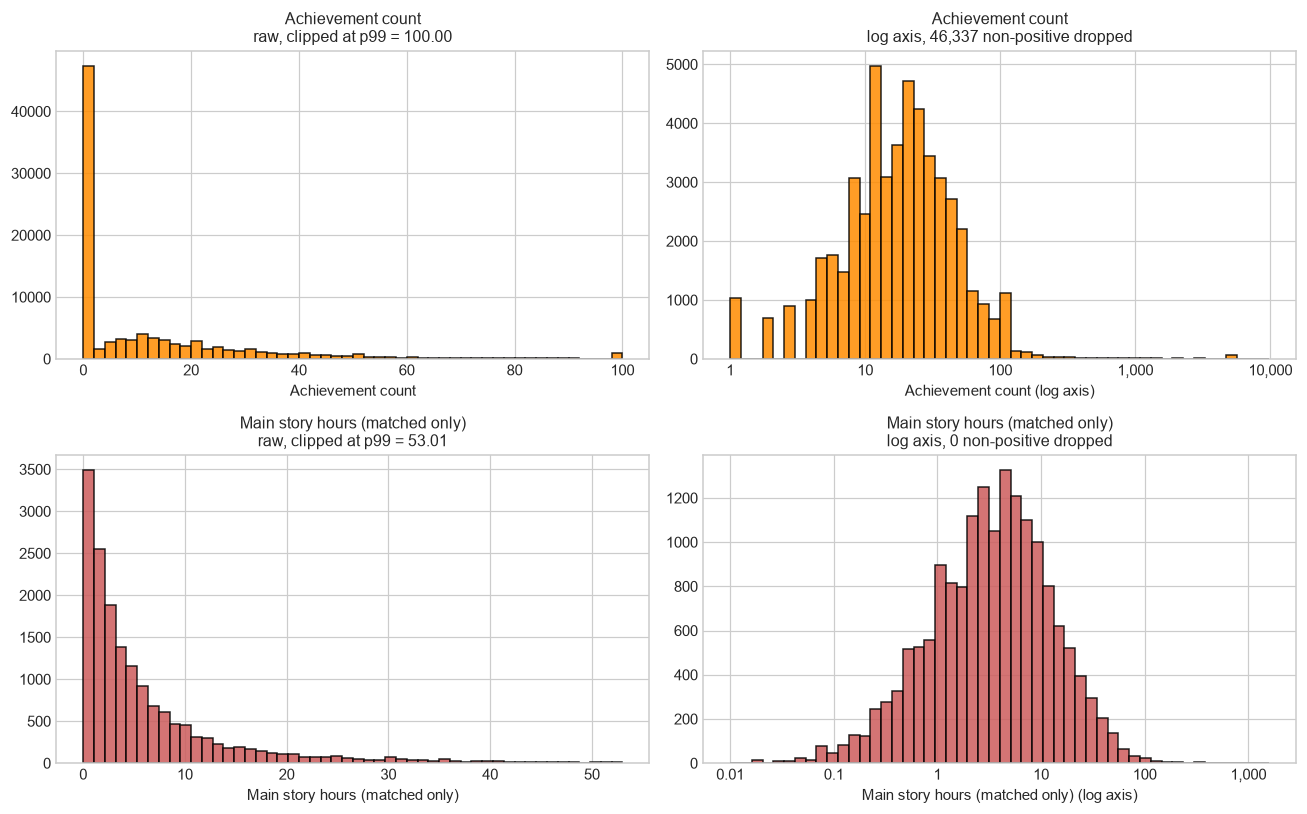

In [6]:
# Heavy-tailed variables, shown raw and then on a log axis
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
raw_vs_log(axes[0], df["steam_achievements"], "Achievement count", "darkorange")
raw_vs_log(axes[1], matched["hltb_main_story"], "Main story hours (matched only)", "indianred")
plt.tight_layout()
save_fig(fig, "01_q1_heavy_tailed_raw_vs_log")
plt.show()

**Author**: Lee Sin Yang

The number of achievements follows a somewhat log-normal distribution, though it has long right tail. The majority of games have 0 achievements. 

The expected number of hours from HLTB also follows a somewhat log-normal distribution. It is slightly less symmetrical, with more games less than the mean than more.

In [7]:
def top_tokens(series, n=12):
    tok = series.fillna("").str.split(",").explode().str.strip()
    tok = tok[tok.ne("")]
    out = tok.value_counts().head(n).to_frame("games")
    out["pct_of_rows"] = (out["games"] / len(series) * 100).round(1)
    return out

for name in ["steam_genres", "steam_categories"]:
    print(f"--- Top {name} ---")
    print(top_tokens(df[name]).to_string())
    print()

--- Top steam_genres ---
                       games  pct_of_rows
steam_genres                             
Indie                  64018         66.0
Casual                 39949         41.2
Action                 36783         37.9
Adventure              35483         36.6
Simulation             19308         19.9
Strategy               17739         18.3
RPG                    16151         16.6
Free To Play            9418          9.7
Early Access            8968          9.2
Sports                  3912          4.0
Racing                  3271          3.4
Massively Multiplayer   1871          1.9

--- Top steam_categories ---
                            games  pct_of_rows
steam_categories                              
Single-player               85838         88.5
Family Sharing              76547         78.9
Steam Achievements          45034         46.4
Steam Cloud                 24640         25.4
Full controller support     20514         21.1
Multi-player                

### Interpretation: What the data looks like
**Author**: Lee Sin Yang
<!-- Describe the shape of the training set and the distribution of the main variables. Cover which variables are heavily skewed or zero-inflated, whether the log view changes what you conclude from the raw view, which variables will need a transformation before modelling, how concentrated the release years are, and which genres and categories dominate the catalogue. -->
Overall, the data presents some key data quality issues. The most important one is that due to the matching between datasets, most rows did not get matched as they are likely to be simple games that did not get much popularity. This extends further into the characteristics of these games, as a noticeable amount of them have no achievements (a controllable variable) and only support one language (another controllable variable).


## 2. Missingness and data anomalies
*Code: Generated by AI Assistant*

*Written by AI Assistant*: a zero in this data can mean three different things, so they are separated below: a sentinel for absent, an unobserved outcome, and a genuine value such as a free-to-play price. Three anomalies follow: software sold on Steam that is not a game, implausible playtimes, and duplicate or inconsistent keys.

In [8]:
# Three different kinds of absence, which pandas shows identically as 0 or NaN
sentinel = pd.DataFrame([
    {"column": "steam_metacritic_score", "kind": "0 means absent", "n": int((df["steam_metacritic_score"] == 0).sum())},
    {"column": "steam_median_playtime_forever", "kind": "0 means SteamSpy could not estimate", "n": int((df["steam_median_playtime_forever"] == 0).sum())},
    {"column": "steam_review_count", "kind": "0 means outcome never observed", "n": int((df["steam_review_count"] == 0).sum())},
    {"column": "steam_price", "kind": "0 is a real value, free-to-play", "n": int((df["steam_price"] == 0).sum())},
    {"column": "steam_achievements", "kind": "0 is a real value, no achievements", "n": int((df["steam_achievements"] == 0).sum())},
    {"column": "hltb_main_story", "kind": "NaN means unmatched or no HLTB time", "n": int(df["hltb_main_story"].isna().sum())},
])
sentinel["pct"] = (sentinel["n"] / len(df) * 100).round(1)
print(sentinel.to_string(index=False))
print("\nColumns with true nulls:")
print(df.isna().sum()[lambda s: s > 0].sort_values(ascending=False).head(15).to_string())

                       column                                kind     n  pct
       steam_metacritic_score                      0 means absent 93650 96.5
steam_median_playtime_forever 0 means SteamSpy could not estimate 76364 78.7
           steam_review_count      0 means outcome never observed 32477 33.5
                  steam_price     0 is a real value, free-to-play 20117 20.7
           steam_achievements  0 is a real value, no achievements 46337 47.8
              hltb_main_story NaN means unmatched or no HLTB time 80366 82.8

Columns with true nulls:
steam_movies                   97026
steam_score_rank               96993
hltb_versus                    96530
hltb_versus_polled             96530
hltb_co_op_polled              95922
hltb_co_op                     95922
steam_metacritic_url           93650
steam_reviews                  87390
hltb_main_plus_sides_polled    86187
hltb_main_plus_sides           86088
hltb_completionist_polled      85193
hltb_completionist          

**Author**: Lee Sin Yang

Of the null values, most are HLTB fields (no match). Price and number of achievements have a true 0, meaning a free game or having no achievements.

In [9]:
# Anomaly 1: rows that are software rather than games
NON_GAME_GENRES = {
    "Utilities", "Design & Illustration", "Animation & Modeling", "Audio Production",
    "Video Production", "Photo Editing", "Software Training", "Web Publishing",
    "Game Development", "Accounting",
}
genre_sets = df["steam_genres"].fillna("").apply(lambda x: {t.strip() for t in x.split(",")})
df["steam_is_software"] = genre_sets.apply(lambda s: bool(NON_GAME_GENRES & s))

print(f"rows carrying a non-game genre: {df['steam_is_software'].sum():,} ({df['steam_is_software'].mean() * 100:.1f}%)")
print(f"  among the 100 highest playtimes: {df.nlargest(100, 'steam_playtime_hours')['steam_is_software'].sum()}")
print(f"  among matched rows: {df.loc[df['matched_hltb'], 'steam_is_software'].sum():,} of {int(df['matched_hltb'].sum()):,}")
show = df[df["steam_is_software"]].nlargest(8, "steam_playtime_hours")[
    ["steam_name", "steam_playtime_hours", "steam_review_count", "steam_genres"]].copy()
show["steam_name"] = ascii_names(show["steam_name"])
show["steam_genres"] = ascii_names(show["steam_genres"])
show.round(1)

rows carrying a non-game genre: 1,329 (1.4%)
  among the 100 highest playtimes: 17
  among matched rows: 7 of 16,660


,steam_name,steam_playtime_hours,steam_review_count,steam_genres
3476,VEGAS Pro 18 Edit Steam Edition,3084.3,2337,"Audio Production,Video Production"
10008,Energy Engine PC Live Wallpaper,1605.4,347,"Design & Illustration,Utilities"
19645,Reality Mixer - Mixed Reality for VR headsets,1078.8,81,Utilities
6726,Boom 3D Windows: Experience 3D surround sound ...,1044.6,730,"Audio Production,Utilities"
25285,Mosaico,961.3,44,Utilities
7008,RainWallpaper,957.3,677,"Animation & Modeling,Design & Illustration,Uti..."
15858,MediBang Paint for Desktop,709.2,132,"Animation & Modeling,Design & Illustration,Pho..."
4604,XSOverlay,675.9,1443,"Utilities,Early Access"


**Author**: Lee Sin Yang

While Steam is a primarily game platform, it also has different software that are productivity-focused. The usage patterns differ, with software likely to have less users but longer usage time (for freelancers, small businesses, etc). 1.4% of the dataset is not a game, but 16 of them are part of the top 100 in median playtime, indicating confirmation of this usage pattern. This also extends to the HLTB match, as software is by its nature unlikely to appear there.

In [10]:
# Anomaly 2: implausible playtime
print(f"playtime > 1,000 h : {(df['steam_playtime_hours'] > 1000).sum():,} games")
print(f"playtime > 8,760 h : {(df['steam_playtime_hours'] > 8760).sum():,} games (more than a year of wall-clock)")
print(f"playtime == 0      : {(df['steam_playtime_hours'] == 0).sum():,} games ({(df['steam_playtime_hours'] == 0).mean() * 100:.1f}%)")

extreme = df.nlargest(10, "steam_playtime_hours")[
    ["steam_name", "steam_playtime_hours", "steam_review_count", "steam_owners_lower", "steam_price", "steam_genres"]].copy()
extreme["steam_name"] = ascii_names(extreme["steam_name"])
extreme["steam_genres"] = ascii_names(extreme["steam_genres"]).str.slice(0, 38)
extreme.round(1)

playtime > 1,000 h : 22 games
playtime > 8,760 h : 1 games (more than a year of wall-clock)
playtime == 0      : 76,364 games (78.7%)


,steam_name,steam_playtime_hours,steam_review_count,steam_owners_lower,steam_price,steam_genres
25174,Avem33,57159.1,44,50000,0.0,"Casual,Free To Play,Indie,Racing"
6001,Letters From a Rainy Day -Oceans and Lace-,5994.6,897,20000,11.9,Adventure
10374,?? Lover,5383.0,324,0,2.4,"Casual,Indie,RPG"
5479,Sisyphus Reborn,3706.8,1052,50000,0.0,Adventure
3476,VEGAS Pro 18 Edit Steam Edition,3084.3,2337,200000,45.0,"Audio Production,Video Production"
80838,FURRY HITLER 2,2844.6,0,0,3.5,"Adventure,Casual"
29105,Glitchball,2828.3,31,0,0.0,"Casual,Free To Play,Indie,Sports"
12261,Love Stories: When Pastel Meets Grotesque,2646.3,230,20000,0.8,Adventure
12793,Desktop Kitten Girl,2349.2,210,0,3.2,"Adventure,Casual,Indie,RPG,Simulation"
3254,GINKA,1622.2,2604,100000,13.8,"Adventure,Casual"


**Author**: Lee Sin Yang

In terms of outliers by median playtime, we identified 23 games with more than 1000 median hours (or about 42 straight days), and one game with a clear outlier at 57k hours. Most of these games are niche, with a low number of players leading to the median being pulled up by anomalous users. Most games (78.7%) have no median playtime, part of the long right tail of unpopular games discovered earlier.

In [11]:
# Anomaly 3: duplicate and near-duplicate titles, and date problems
print(f"duplicate steam_appid: {df['steam_appid'].duplicated().sum():,}")
print(f"duplicate normalised titles: {df['title_key'].duplicated().sum():,}  (stage 00 already reduced these)")
print(f"missing Steam release year: {df['steam_year'].isna().sum():,}")
print(f"release year beyond the snapshot year ({config.SNAPSHOT_YEAR}): {(df['steam_year'] > config.SNAPSHOT_YEAR).sum():,}")
print(f"hltb_main_story <= 0 among matched: {(matched['hltb_main_story'] <= 0).sum():,}")
print("\nSteam year minus HowLongToBeat year, matched games:")
print(matched["year_diff"].describe(percentiles=[0.05, 0.5, 0.95]).round(2).to_string())

duplicate steam_appid: 0
duplicate normalised titles: 0  (stage 00 already reduced these)
missing Steam release year: 0
release year beyond the snapshot year (2026): 0
hltb_main_story <= 0 among matched: 0

Steam year minus HowLongToBeat year, matched games:
count    16660.00
mean        17.64
std        180.56
min         -7.00
5%           0.00
50%          0.00
95%         11.00
max       2026.00


**Author**: Lee Sin Yang

No other obvious data quality issues in terms of duplicates and impossible data. Steam year and HLTB year differs slightly, but generally HLTB lists games as more recent than they are on Steam.

## 3. What are our prospective target variables?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this section is the evidence for AQ1. Six candidates are compared on coverage, zero inflation, skew and outliers, including the completion ratio. Each heavy-tailed candidate is shown untransformed and then on a log scale.

In [12]:
candidates = {
    "steam_positive_rate": df["steam_positive_rate"],
    "steam_review_count": df["steam_review_count"].astype(float),
    "steam_metacritic_score": df.loc[df["steam_metacritic_score"] > 0, "steam_metacritic_score"].astype(float),
    "steam_playtime_hours": df["steam_playtime_hours"],
    "steam_owners_lower": df["steam_owners_lower"],
    "completion_ratio": matched["completion_ratio"],
}
rows = []
for name, s in candidates.items():
    rows.append({
        "target": name,
        "n_defined": int(s.notna().sum()),
        "pct_of_train": round(s.notna().sum() / len(df) * 100, 1),
        "pct_zero": round(float((s == 0).mean() * 100), 1),
        "median": round(float(s.median()), 3),
        "mean": round(float(s.mean()), 3),
        "skew": round(float(s.skew()), 2),
        "p99": round(float(s.quantile(0.99)), 2),
        "max": round(float(s.max()), 2),
    })
pd.DataFrame(rows).set_index("target")

,n_defined,pct_of_train,pct_zero,median,mean,skew,p99,max
target,,,,,,,,
steam_positive_rate,64549,66.5,2.0,0.819,0.759,-1.33,1.00,1.000000e+00
steam_review_count,97026,100.0,33.5,7.000,1205.175,178.37,15179.50,8.815087e+06
steam_metacritic_score,3376,3.5,0.0,76.000,73.787,-1.04,92.00,9.700000e+01
steam_playtime_hours,97026,100.0,78.7,0.000,2.771,291.03,26.25,5.715907e+04
steam_owners_lower,97026,100.0,79.4,0.000,49489.621,75.53,1000000.00,1.000000e+08
completion_ratio,16660,17.2,35.1,0.308,2.185,87.25,13.31,7.722470e+03


**Author**: Lee Sin Yang

We evaluate 6 different metrics of what a "popular" game can be. Review count, playtime hours, and number of owners has the most number of data points at 97026. However, these may not translate to good overall sales as they only factor in the number of people it has reached and not reception (which is admittedly somewhat correlated), and playtime hours and number of owners has many zero values. The positive review rate has 64000 data points, but each is an aggregation of the proportion per game already. Metacritic score is the most selective, with only 3365 games appearing on metacritic. Completion ratio which we propose has only 16660 games. Apart from the positive rate and metacritic scores (which are proportions), the rest have high skew with the long right tail.

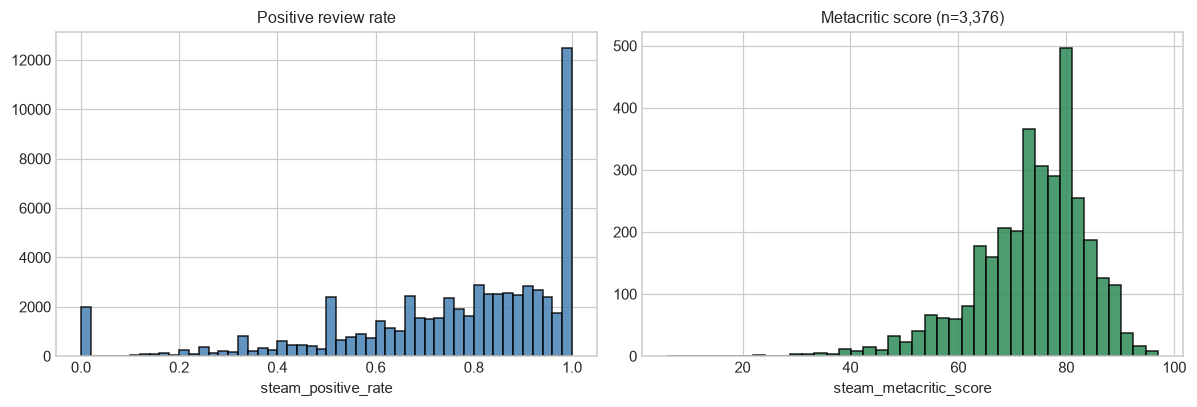

In [13]:
# Candidate targets that need no transformation
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["steam_positive_rate"].dropna(), bins=50, color="steelblue", edgecolor="black", alpha=0.85)
axes[0].set_title("Positive review rate")
axes[0].set_xlabel("steam_positive_rate")
mc = df.loc[df["steam_metacritic_score"] > 0, "steam_metacritic_score"]
axes[1].hist(mc, bins=40, color="seagreen", edgecolor="black", alpha=0.85)
axes[1].set_title(f"Metacritic score (n={len(mc):,})")
axes[1].set_xlabel("steam_metacritic_score")
plt.tight_layout()
save_fig(fig, "01_q3_targets_untransformed")
plt.show()

**Author**: Lee Sin Yang

Looking at the 2 review rate metrics, positive review rate has clear peaks at 0, 0.5 and 1.0. This is consistent with low review games having only a few reviews that are positive and negative. Overall, the positive review rate leans positive (majority > 0.5).

Metacritic score has a main spike at 80, close to the mean of around 75. It follows a somewhat normal distribution, but with more values on the left of the mean than the right. Metacritic score is a cleaner metric but has much lower sample size.

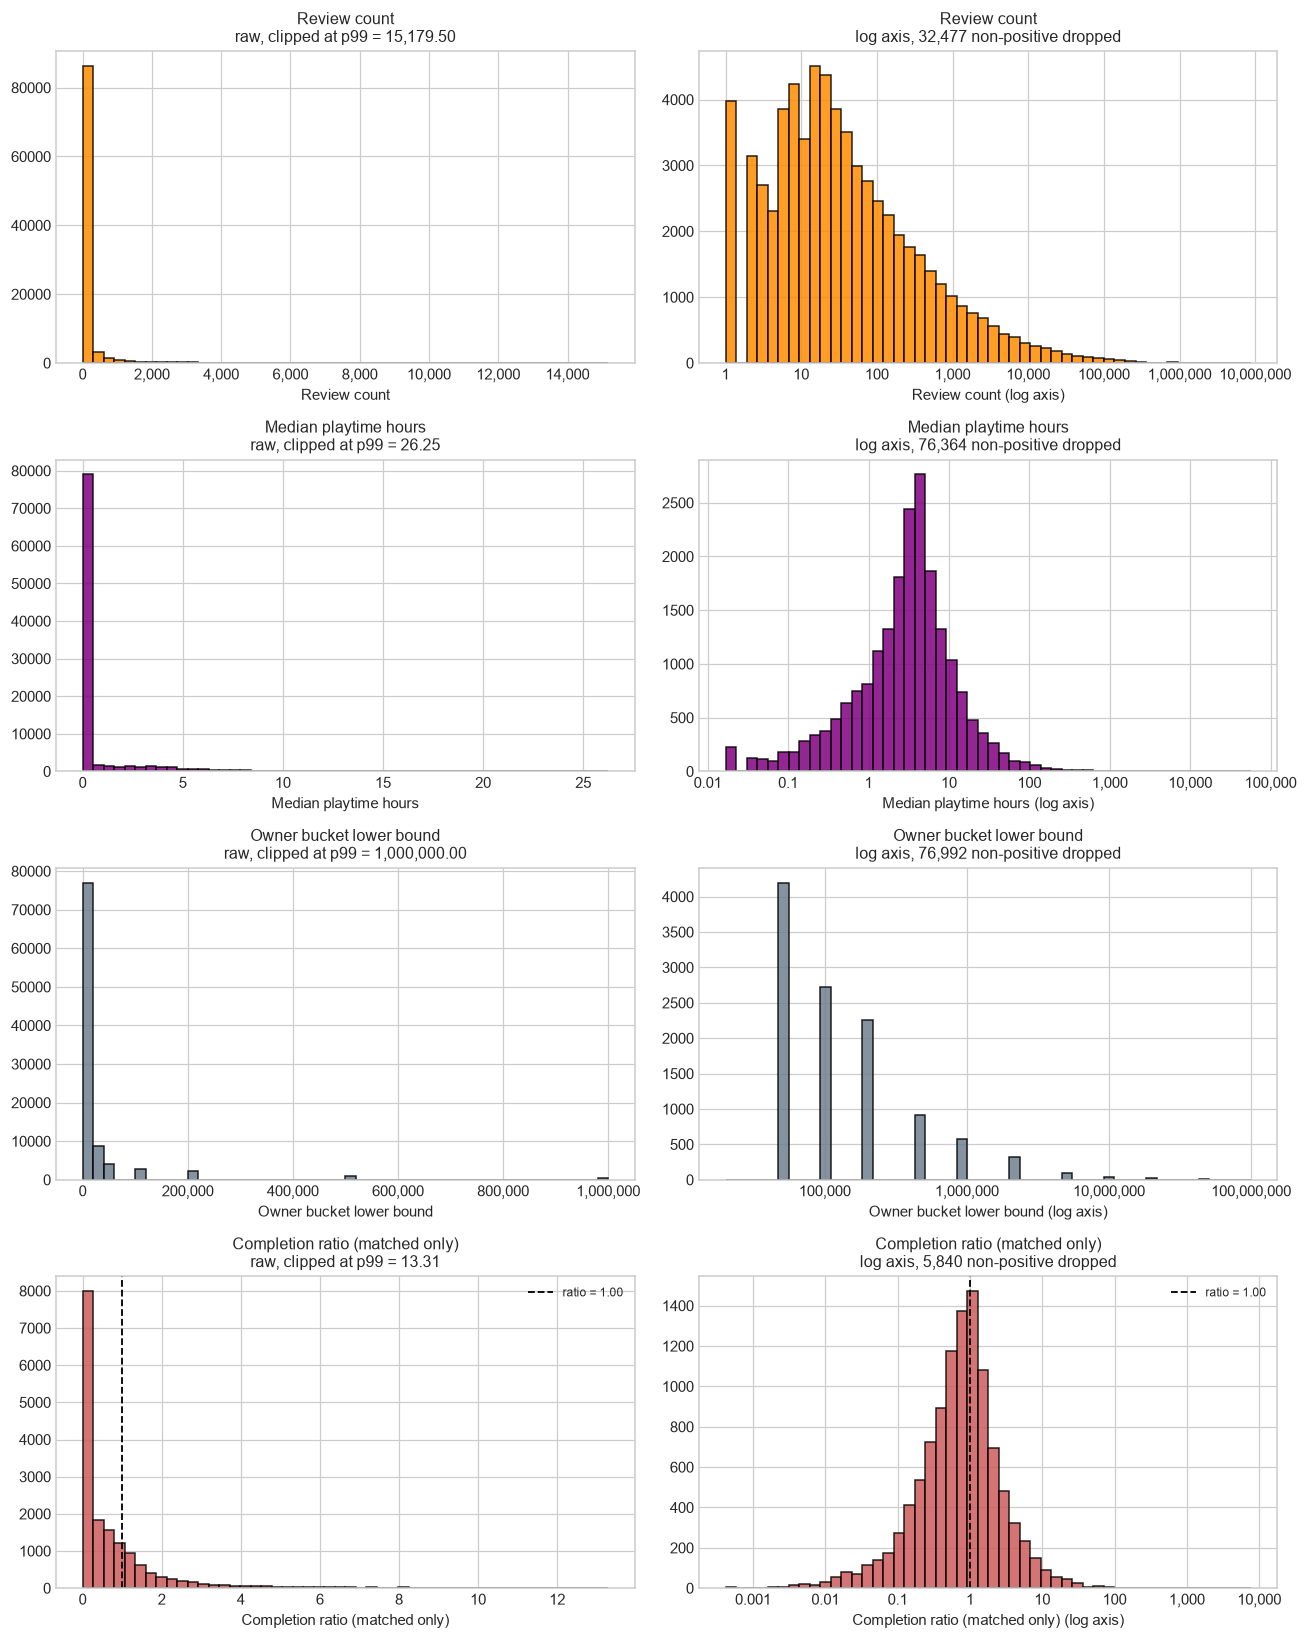

In [14]:
# Heavy-tailed candidate targets, raw on the left and on a log axis on the right
fig, axes = plt.subplots(4, 2, figsize=(12, 15))
raw_vs_log(axes[0], df["steam_review_count"].astype(float), "Review count", "darkorange")
raw_vs_log(axes[1], df["steam_playtime_hours"], "Median playtime hours", "purple")
raw_vs_log(axes[2], df["steam_owners_lower"], "Owner bucket lower bound", "slategray")
raw_vs_log(axes[3], matched["completion_ratio"], "Completion ratio (matched only)", "indianred")
axes[3][1].axvline(1, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[3][1].legend(fontsize=8)
axes[3][0].axvline(1, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[3][0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_q3_targets_raw_vs_log")
plt.show()

**Author**: Lee Sin Yang

The 4 other metrics are heavily 0-spiked with long right tails, thus we log transform them and filter the 0s to better see the differences.

Most games have around 0-50 reviews, with a gradual decline in log-scale afterwards. Median playtime hours peaks around 5 hours, following a somewhat lognormal distribution. The owner bucket lower bound is actually a categorical variable, as they are in buckets. There are only a small number (<1000) games with more than 1M owners. To account for games having different targeted hours (e.g. an indie game might have low hours, while a big AAA game might have high hours), we propose completion ratio as the median steam hours divided by the expected number of hours to complete. Completion ratio follows the most lognormal distribution, centred around the 1.0 ratio. 

In [15]:
# The completion ratio in detail: zero inflation, tail, and its two components
cr_all = matched["completion_ratio"]
print(f"matched games               : {len(matched):,}")
print(f"  completion ratio is zero  : {(cr_all == 0).sum():,} ({(cr_all == 0).mean() * 100:.1f}%)  <- SteamSpy playtime of 0")
print(f"  ratio in (0, 1]           : {((cr_all > 0) & (cr_all <= 1)).sum():,}")
print(f"  ratio > 1                 : {(cr_all > 1).sum():,}")
print(f"  ratio > 5                 : {(cr_all > 5).sum():,}")
print("\nquantiles of the positive ratio:")
print(cr_all[cr_all > 0].quantile([0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3).to_string())

matched games               : 16,660
  completion ratio is zero  : 5,840 (35.1%)  <- SteamSpy playtime of 0
  ratio in (0, 1]           : 6,508
  ratio > 1                 : 4,312
  ratio > 5                 : 616

quantiles of the positive ratio:
0.01     0.011
0.25     0.338
0.50     0.772
0.75     1.481
0.95     5.477
0.99    18.952


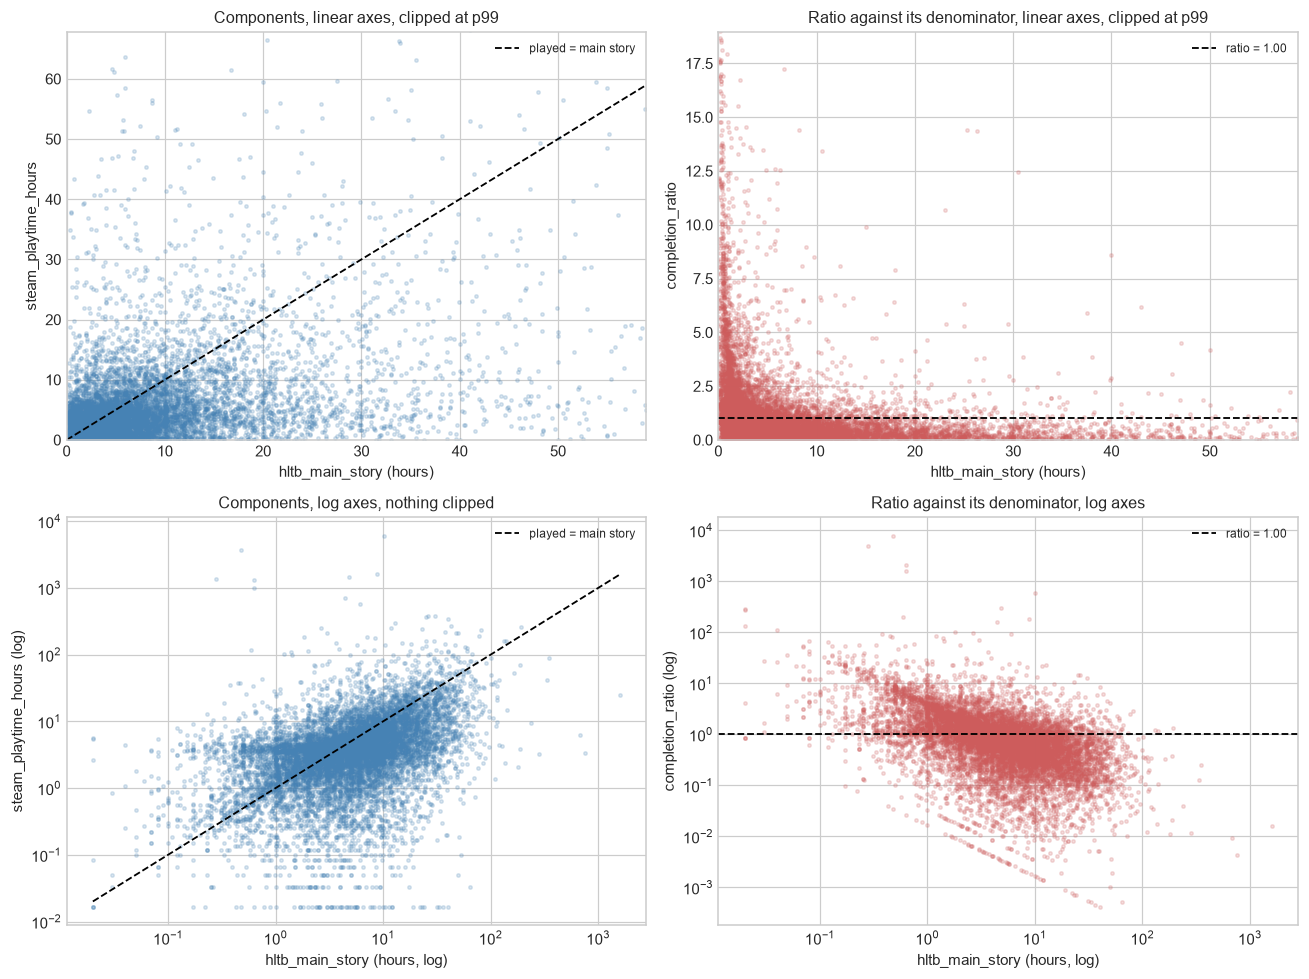

The right-hand panels divide by the quantity on their x axis, so a negative slope
appears from arithmetic alone. The left-hand panels show the same data without that.


In [16]:
# The two components, and the ratio, on linear axes and then on log axes
pos = matched[(matched["completion_ratio"] > 0) & (matched["hltb_main_story"] > 0)]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Row 0: linear axes, clipped so the bulk is visible
xc, yc = pos["hltb_main_story"].quantile(0.99), pos["steam_playtime_hours"].quantile(0.99)
axes[0, 0].scatter(pos["hltb_main_story"], pos["steam_playtime_hours"], s=5, alpha=0.2, color="steelblue")
axes[0, 0].plot([0, xc], [0, xc], color="black", linestyle="--", linewidth=1.2, label="played = main story")
axes[0, 0].set_xlim(0, xc); axes[0, 0].set_ylim(0, yc)
axes[0, 0].set_xlabel("hltb_main_story (hours)"); axes[0, 0].set_ylabel("steam_playtime_hours")
axes[0, 0].set_title("Components, linear axes, clipped at p99")
axes[0, 0].legend(fontsize=8)

axes[0, 1].scatter(pos["hltb_main_story"], pos["completion_ratio"], s=5, alpha=0.2, color="indianred")
axes[0, 1].axhline(1.0, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[0, 1].set_xlim(0, xc); axes[0, 1].set_ylim(0, pos["completion_ratio"].quantile(0.99))
axes[0, 1].set_xlabel("hltb_main_story (hours)"); axes[0, 1].set_ylabel("completion_ratio")
axes[0, 1].set_title("Ratio against its denominator, linear axes, clipped at p99")
axes[0, 1].legend(fontsize=8)

# Row 1: the same two plots on log axes
axes[1, 0].scatter(pos["hltb_main_story"], pos["steam_playtime_hours"], s=5, alpha=0.2, color="steelblue")
lims = [pos["hltb_main_story"].min(), pos["hltb_main_story"].max()]
axes[1, 0].plot(lims, lims, color="black", linestyle="--", linewidth=1.2, label="played = main story")
axes[1, 0].set_xscale("log"); axes[1, 0].set_yscale("log")
axes[1, 0].set_xlabel("hltb_main_story (hours, log)"); axes[1, 0].set_ylabel("steam_playtime_hours (log)")
axes[1, 0].set_title("Components, log axes, nothing clipped")
axes[1, 0].legend(fontsize=8)

axes[1, 1].scatter(pos["hltb_main_story"], pos["completion_ratio"], s=5, alpha=0.2, color="indianred")
axes[1, 1].axhline(1.0, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[1, 1].set_xscale("log"); axes[1, 1].set_yscale("log")
axes[1, 1].set_xlabel("hltb_main_story (hours, log)"); axes[1, 1].set_ylabel("completion_ratio (log)")
axes[1, 1].set_title("Ratio against its denominator, log axes")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
save_fig(fig, "01_q3_completion_ratio_raw_vs_log")
plt.show()
print("The right-hand panels divide by the quantity on their x axis, so a negative slope")
print("appears from arithmetic alone. The left-hand panels show the same data without that.")

**Author**: Lee Sin Yang

The scatter plot of steam playtime hours against HLTB hours (top left) shows the distribution of games, which is not a clean diagonal line. Instead, the main cluster is in <10 hours on both, with more sporadic points as both values increase. When turning this into the completion ratio, most of the high completion ratios are due to low HLTB hours (i.e., low hours to complete hence a high ratio).

By log transforming the axes, we can see a better trend. Most values cluster in the center, roughly along the diagonal line of a 1.0 ratio. After creating the ratio on a log scale, the values are all fairly clustered and centered around 1.0. 

*Written by AI Assistant*: whether a completion ratio exists at all, and how noisy it is when it does, depends on the evidence behind each side of it. The numerator rests on Steam's audience, for which review count stands in, and the denominator on the number of HowLongToBeat reports. The spread of the log ratio is used because, as the log-axis panels above show, the log scale is where the ratio is roughly symmetric.

In [17]:
# Zero ratios and noise, against the evidence behind each side of the ratio
ratio_frame = matched.copy()
ratio_frame["ratio_is_zero"] = ratio_frame["completion_ratio"].eq(0)
ratio_nonzero = ratio_frame[~ratio_frame["ratio_is_zero"]].copy()
ratio_nonzero["log_ratio"] = np.log(ratio_nonzero["completion_ratio"])

review_bins = [-1, 0, 10, 50, 200, 1000, 5000, np.inf]
review_labels = ["0", "1-10", "11-50", "51-200", "201-1k", "1k-5k", "5k+"]
for frame in (ratio_frame, ratio_nonzero):
    frame["review_band"] = pd.cut(frame["steam_review_count"], bins=review_bins, labels=review_labels)

by_reviews = ratio_frame.groupby("review_band", observed=True).agg(
    games=("ratio_is_zero", "size"),
    pct_ratio_zero=("ratio_is_zero", lambda s: s.mean() * 100),
)
by_reviews["sd_log_ratio"] = ratio_nonzero.groupby("review_band", observed=True)["log_ratio"].std()
by_reviews["median_ratio"] = ratio_nonzero.groupby("review_band", observed=True)["completion_ratio"].median()
print("Numerator side, by Steam review count (matched games)")
print(by_reviews.round(2).to_string())

poll_bins = [0, 1, 4, 10, 50, np.inf]
poll_labels = ["1", "2-4", "5-10", "11-50", "50+"]
ratio_nonzero["poll_band"] = pd.cut(ratio_nonzero["hltb_main_story_polled"], bins=poll_bins, labels=poll_labels)
by_polls = ratio_nonzero.groupby("poll_band", observed=True)["log_ratio"].agg(games="size", sd_log_ratio="std")
print("\nDenominator side, by HowLongToBeat main-story poll count (non-zero ratios only)")
print(by_polls.round(2).to_string())

for cut in (50, 200, 1000):
    sub = ratio_frame[ratio_frame["steam_review_count"] >= cut]
    print(f"\nat >= {cut:>4} reviews: {len(sub):,} matched games, "
          f"{sub['ratio_is_zero'].mean() * 100:.1f}% zero, {int((~sub['ratio_is_zero']).sum()):,} usable ratios", end="")
print()

print("\nSpearman correlation with the log ratio, non-zero ratios only:")
for col in ["steam_review_count", "steam_positive_rate"]:
    print(f"  {col}: {ratio_nonzero['log_ratio'].corr(ratio_nonzero[col], method='spearman'):.3f}")
print(f"  for comparison, ratio against review count with zeros included: "
      f"{ratio_frame['completion_ratio'].corr(ratio_frame['steam_review_count'], method='spearman'):.3f}")

Numerator side, by Steam review count (matched games)
             games  pct_ratio_zero  sd_log_ratio  median_ratio
review_band                                                   
0             2153           69.81          1.43          0.89
1-10           438           98.40          1.75          0.10
11-50         2076           84.54          1.92          0.56
51-200        3707           43.97          1.79          0.81
201-1k        4262           10.53          1.38          0.92
1k-5k         2473            2.22          1.14          0.70
5k+           1551            1.10          0.85          0.60

Denominator side, by HowLongToBeat main-story poll count (non-zero ratios only)
           games  sd_log_ratio
poll_band                     
1           2103          1.72
2-4         2767          1.53
5-10        1921          1.42
11-50       2426          1.16
50+         1601          0.81

at >=   50 reviews: 12,036 matched games, 18.1% zero, 9,857 usable ratios
at >= 

**Author**: [Insert Name]  
<!-- Interpret how the share of zero ratios and the spread of the log ratio change with Steam review count and with HowLongToBeat poll count. Cover what this implies for a minimum review threshold, what that threshold costs in games, whether review count and poll count should weight the ratio in AQ2, and why the correlation with review count changes so much once the zeros are removed. -->
With more data points, the sd of the ratio decreases. The more important observation is that the perecntage of zero completion ratio from 0-200 reviews hovers around 44-98%, while at 200+ it is only 10%.

In [18]:
def extremes(frame, col, n=5):
    sub = frame[frame[col].notna()]
    out = pd.concat([sub.nlargest(n, col), sub.nsmallest(n, col)])[
        ["steam_name", col, "steam_review_count", "steam_playtime_hours", "hltb_main_story"]].copy()
    out["steam_name"] = ascii_names(out["steam_name"])
    return out.round(2)

print("--- Highest and lowest completion ratio (positive only) ---")
print(extremes(matched[matched["completion_ratio"] > 0], "completion_ratio").to_string(index=False))
print("\n--- Highest and lowest positive rate, among games with at least 500 reviews ---")
print(extremes(df[df["steam_review_count"] >= 500], "steam_positive_rate").to_string(index=False))

--- Highest and lowest completion ratio (positive only) ---
                                        steam_name  completion_ratio  steam_review_count  steam_playtime_hours  hltb_main_story
                                   Sisyphus Reborn           7722.47                1052               3706.78             0.48
                                       Rogue Agent           4897.20                 409               1371.22             0.28
                            My Stepbro is a Femboy           2111.72                   0               1330.38             0.63
                   Shan Gui II: Sweet Osmanthus II           1576.14                 520                992.97             0.63
        Letters From a Rainy Day -Oceans and Lace-            592.93                 897               5994.57            10.11
                                        7th Legion              0.00                  90                  0.02            40.00
                                    Mato Ano

### Interpretation: Choosing a target variable
**Author**: Lee Sin Yang 
<!-- This is the answer to AQ1. Evaluate each candidate target against what a studio needs to know and what the data can support: how many games it is defined for, how it is distributed on both the raw and log views, what its outliers are and whether they are real, and whether it measures success or merely exposure. Address the completion ratio directly, including its zero inflation and what the two components show when plotted separately. State which target or targets you carry into AQ2 and AQ3, and why you set the others aside. -->
Of the various metrics, we can identify 2 main types of "popularity" - how widespread it is (number of reviews, owners) and satisfaction (rating, completion ratio). Of these two categories, we move ahead with the number of reviews, positive review rating, and completion ratio as these have the most number of data points. For completion ratio, while it might not have the most data points, it might paint a truer picture of game reception than review rating as steam reviews can be comedic (e.g. rating negative while having 1000 hours played), and only users with strong opinions will leave a review. We believe that completion ratio, a numbers-backed approach, reveals more about true user behaviour. We keep positive review rate as a backup metric, but completion ratio is our main metric.

Number of reviews materially affects the completion ratio, with games over 200 reviews having only 10% 0 completion ratio while <10 reviews having 98.2%. Thus, we will filter by reviews for our modelling as these zero values are essentially data points that have not discovered their true value. While these would introduce some bias, a model trained with the zero ratios included (due to an inability to measure playtime) would introduce much more noise.


## 4. What do the top games look like on each chosen target?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this section depends on section 3. It uses the three targets carried forward from the section 3 interpretation: review count, positive review rate, and completion ratio. A top game is one in the highest 1% on that target. Software rows from section 2 are excluded throughout. The positive rate and the completion ratio are only ranked among games with at least 500 reviews, because a rate built on a handful of reviews puts noise at the top rather than success, and because almost every game below that level has a completion ratio of zero (see the table at the end of section 3).

In [19]:
# Top games per chosen target from section 3
TARGETS = ["steam_review_count", "steam_positive_rate", "completion_ratio"]
assert set(TARGETS) <= set(candidates), "every chosen target must be one of the section 3 candidates"

TOP_SHARE = 0.01
MIN_REVIEWS_FOR_RATES = 500

eligible = df[~df["steam_is_software"]]
top_pools = {
    "steam_review_count": eligible,
    "steam_positive_rate": eligible[eligible["steam_review_count"] >= MIN_REVIEWS_FOR_RATES],
    "completion_ratio": eligible[eligible["matched_hltb"]
                                 & (eligible["completion_ratio"] > 0)
                                 & (eligible["steam_review_count"] >= MIN_REVIEWS_FOR_RATES)],
}
assert list(top_pools) == TARGETS

top_sets, rows = {}, []
for metric, pool in top_pools.items():
    cut = pool[metric].quantile(1 - TOP_SHARE)
    top = pool[pool[metric] >= cut]
    top_sets[metric] = set(top["steam_appid"])
    rows.append({"target": metric, "ranked_among": len(pool), "cut_off": cut, "top_games": len(top)})
pd.DataFrame(rows).set_index("target").round(3)

,ranked_among,cut_off,top_games
target,,,
steam_review_count,95697,15284.520,957
steam_positive_rate,8155,0.985,82
completion_ratio,5506,12.696,56


In [20]:
show_cols = ["steam_name", "steam_review_count", "steam_positive_rate", "steam_metacritic_score",
             "steam_playtime_hours", "completion_ratio", "steam_price"]
for metric, pool in top_pools.items():
    t = pool.nlargest(10, metric)[show_cols].copy()
    t["steam_name"] = ascii_names(t["steam_name"])
    print(f"=== Top 10 by {metric} ===")
    print(t.round(2).to_string(index=False))
    print()

=== Top 10 by steam_review_count ===
                       steam_name  steam_review_count  steam_positive_rate  steam_metacritic_score  steam_playtime_hours  completion_ratio  steam_price
                 Counter-Strike 2             8815087                 0.87                       0                103.95               NaN         0.00
                           Dota 2             2498969                 0.82                      90                 19.25               NaN         0.00
        Grand Theft Auto V Legacy             1990556                 0.87                      96                 97.43               NaN         0.00
                         Terraria             1409473                 0.97                      83                 34.18              0.66         4.99
Tom Clancy's Rainbow Six? Siege X             1398584                 0.84                       0                 41.70               NaN         0.00
                             Rust             12277

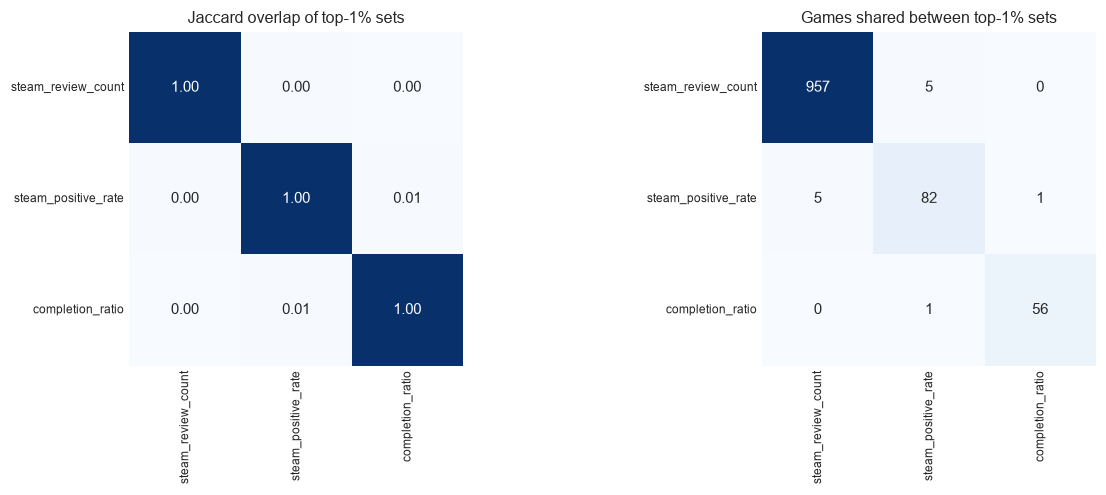

The completion-ratio pool is the matched subset only, which caps its possible overlap.


In [21]:
# Do the targets agree on which games are top? Jaccard overlap between the top sets:
# shared games divided by games in either set. 1 means identical sets, 0 means none shared.
names = list(top_sets)
jac = pd.DataFrame(index=names, columns=names, dtype=float)
shared = pd.DataFrame(index=names, columns=names, dtype=int)
for m1 in names:
    for m2 in names:
        union = top_sets[m1] | top_sets[m2]
        shared.loc[m1, m2] = len(top_sets[m1] & top_sets[m2])
        jac.loc[m1, m2] = shared.loc[m1, m2] / len(union) if union else np.nan

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(jac, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, cbar=False, ax=axes[0])
axes[0].set_title("Jaccard overlap of top-1% sets")
sns.heatmap(shared.astype(int), annot=True, fmt="d", cmap="Blues", square=True, cbar=False, ax=axes[1])
axes[1].set_title("Games shared between top-1% sets")
for ax in axes:
    ax.tick_params(labelsize=8)
plt.tight_layout()
save_fig(fig, "01_q4_top_set_overlap")
plt.show()
print("The completion-ratio pool is the matched subset only, which caps its possible overlap.")

### Interpretation: Agreement between metrics on what a top game is
**Author**: [Insert Name]  
<!-- Use the top-10 lists and the overlap matrix to judge whether the candidate metrics agree on which games are successful. Cover which metrics pick out largely the same games, which pick out different ones, and what kinds of game each metric favours. Say what this means for AQ1: if the metrics disagree, choosing one is choosing a definition of success. -->


In [22]:
# Controllable variables: each top set against all eligible games as the reference
profile_vars = ["steam_price", "steam_achievements", "steam_language_count",
                "steam_dlc_count", "steam_years_since_release", "hltb_main_story"]
groups = {f"Top 1% {m}": eligible[eligible["steam_appid"].isin(top_sets[m])] for m in top_pools}
groups["All eligible games"] = eligible

profile = pd.DataFrame({
    g: {"games": len(frame), **{v: frame[v].median() for v in profile_vars}}
    for g, frame in groups.items()
}).T
print("Medians. hltb_main_story covers matched games only.")
profile.round(2)

Medians. hltb_main_story covers matched games only.


,games,steam_price,steam_achievements,steam_language_count,steam_dlc_count,steam_years_since_release,hltb_main_story
Top 1% steam_review_count,957.0,5.99,45.0,11.0,1.0,8.0,13.22
Top 1% steam_positive_rate,82.0,4.84,15.5,2.0,1.0,4.0,3.02
Top 1% completion_ratio,56.0,2.74,10.0,3.0,1.0,7.0,0.47
All eligible games,95697.0,2.39,4.0,1.0,0.0,4.0,3.50


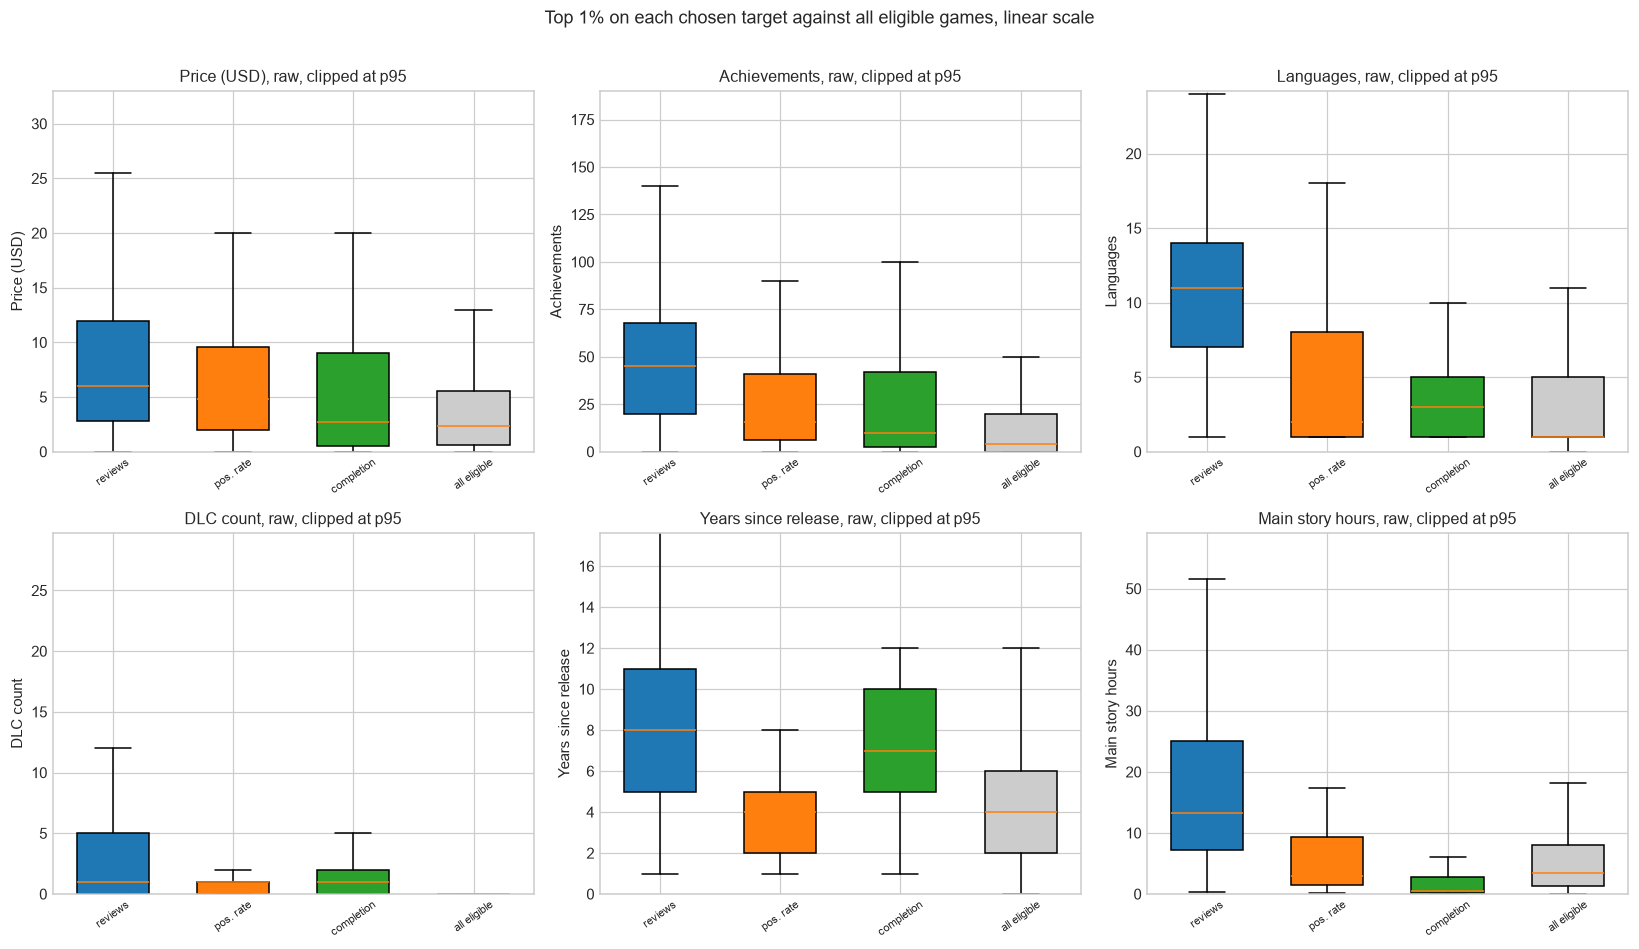

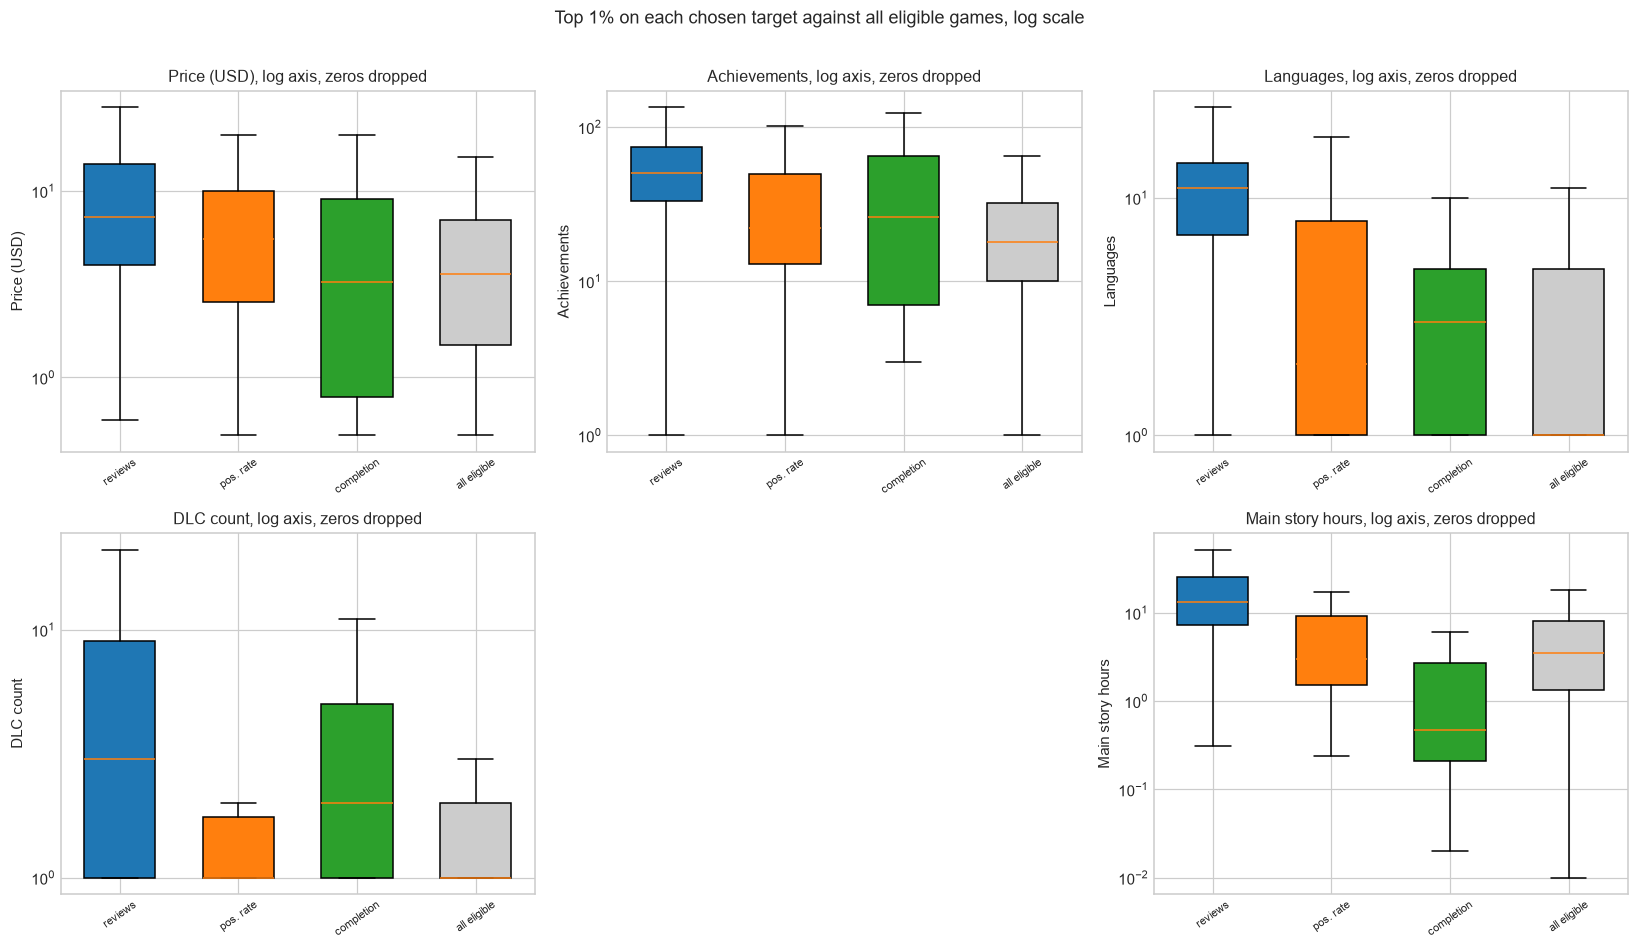

In [23]:
# The same comparison as distributions, raw first and then on a log axis
short = ["reviews", "pos. rate", "completion", "all eligible"]
compare = [
    ("steam_price", "Price (USD)", True),
    ("steam_achievements", "Achievements", True),
    ("steam_language_count", "Languages", True),
    ("steam_dlc_count", "DLC count", True),
    ("steam_years_since_release", "Years since release", False),
    ("hltb_main_story", "Main story hours", True),
]
colours = list(sns.color_palette("tab10", len(groups) - 1)) + [(0.8, 0.8, 0.8)]

def non_empty(values):
    """boxplot needs at least one value per group."""
    return values if len(values) else np.array([np.nan])

for scale in ["linear", "log"]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
    for ax, (col, label, loggable) in zip(axes.ravel(), compare):
        data = [frame[col].dropna() for frame in groups.values()]
        if scale == "log":
            if not loggable:
                ax.set_visible(False)
                continue
            data = [d[d > 0] for d in data]
        bp = ax.boxplot([non_empty(d.values) for d in data], patch_artist=True, showfliers=False, widths=0.6)
        for patch, colour in zip(bp["boxes"], colours):
            patch.set_facecolor(colour)
        ax.set_xticks(range(1, len(short) + 1))
        ax.set_xticklabels(short, rotation=35, fontsize=7.5)
        ax.set_ylabel(label)
        if scale == "log":
            ax.set_yscale("log")
            ax.set_title(f"{label}, log axis, zeros dropped")
        else:
            upper = max((d.quantile(0.95) for d in data if len(d)), default=0)
            if upper > 0:
                ax.set_ylim(0, upper * 1.1)
            ax.set_title(f"{label}, raw, clipped at p95")
    fig.suptitle(f"Top 1% on each chosen target against all eligible games, {scale} scale", y=1.01)
    plt.tight_layout()
    save_fig(fig, f"01_q4_top_by_metric_{scale}")
    plt.show()

### Interpretation: Top games against the rest of the population
**Author**: [Insert Name]  
<!-- Describe how the top games on each metric differ from all eligible games on the controllable variables. Cover which variables separate the top sets from the rest and which overlap too much to tell apart, and whether the pattern is consistent across metrics or specific to one. Say what this implies about predicting success from these variables. -->


## 5. What bias did the merge introduce?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the overall match rate is compared against the rate within audience-size buckets, then matched and unmatched games are compared directly. The standardised mean difference puts variables on a common scale, where an absolute value above 0.1 is the usual threshold for a meaningful imbalance.

In [24]:
steps = [
    ("Training rows", len(df)),
    ("Matched to HowLongToBeat", int(df["matched_hltb"].sum())),
    ("  and hltb_main_story > 0", int(((df["matched_hltb"]) & (df["hltb_main_story"] > 0)).sum())),
    ("  and playtime > 0 (ratio defined and non-zero)", int((df["completion_ratio"] > 0).sum())),
    ("  and at least 50 reviews", int(((df["completion_ratio"] > 0) & (df["steam_review_count"] >= 50)).sum())),
]
funnel = pd.DataFrame(steps, columns=["step", "games"])
funnel["pct_of_train"] = (funnel["games"] / len(df) * 100).round(1)
print(funnel.to_string(index=False))

                                           step  games  pct_of_train
                                  Training rows  97026         100.0
                       Matched to HowLongToBeat  16660          17.2
                        and hltb_main_story > 0  16660          17.2
  and playtime > 0 (ratio defined and non-zero)  10820          11.2
                        and at least 50 reviews   9857          10.2


                     games  matched  match_rate_pct
steam_review_bucket                                
0                    32477     2153             6.6
1-10                 21414      438             2.0
11-50                19337     2076            10.7
51-200               10723     3707            34.6
201-1k                7443     4262            57.3
1k-5k                 3522     2473            70.2
5k-20k                1337      999            74.7
20k+                   773      552            71.4


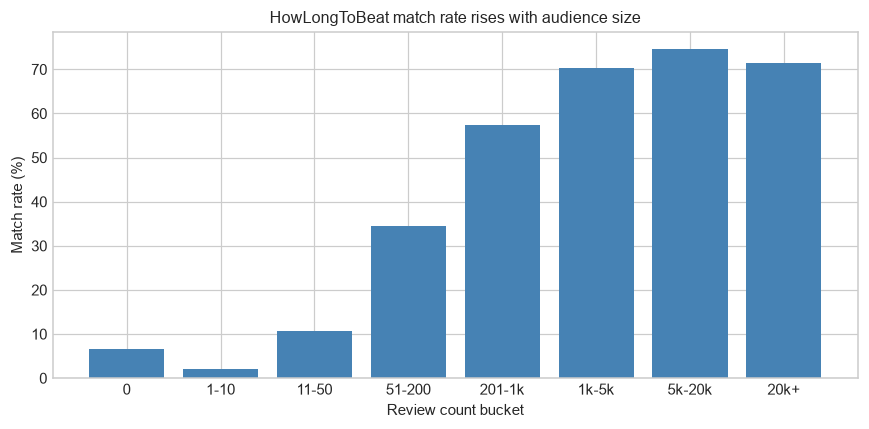

In [25]:
bins = [-1, 0, 10, 50, 200, 1000, 5000, 20000, np.inf]
labels = ["0", "1-10", "11-50", "51-200", "201-1k", "1k-5k", "5k-20k", "20k+"]
df["steam_review_bucket"] = pd.cut(df["steam_review_count"], bins=bins, labels=labels)

by_bucket = df.groupby("steam_review_bucket", observed=True).agg(
    games=("steam_appid", "size"), matched=("matched_hltb", "sum"))
by_bucket["match_rate_pct"] = (by_bucket["matched"] / by_bucket["games"] * 100).round(1)
print(by_bucket.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_bucket.index.astype(str), by_bucket["match_rate_pct"], color="steelblue")
ax.set_ylabel("Match rate (%)"); ax.set_xlabel("Review count bucket")
ax.set_title("HowLongToBeat match rate rises with audience size")
plt.tight_layout()
save_fig(fig, "01_q5_match_rate_by_reviews")
plt.show()

In [26]:
# Matched against unmatched, within single-player games that have some audience.
# Standardised mean difference puts every variable on a comparable scale:
# |SMD| above 0.1 is the usual threshold for a meaningful imbalance.
stratum = df[df["steam_categories"].fillna("").str.contains("Single-player") & (df["steam_review_count"] >= 50)]
a = stratum[stratum["matched_hltb"]]
b = stratum[~stratum["matched_hltb"]]

rows = []
for col in ["steam_review_count", "steam_positive_rate", "steam_price", "steam_achievements",
            "steam_language_count", "steam_years_since_release", "steam_playtime_hours", "steam_metacritic_score"]:
    m1, m2 = a[col].mean(), b[col].mean()
    s1, s2 = a[col].std(), b[col].std()
    pooled = np.sqrt((s1**2 + s2**2) / 2)
    rows.append({"variable": col, "matched_mean": m1, "unmatched_mean": m2,
                 "SMD": (m1 - m2) / pooled if pooled else np.nan})
smd = pd.DataFrame(rows).set_index("variable").round(3)
print(f"stratum: single-player with >= 50 reviews, n = {len(stratum):,}")
print(f"matched {len(a):,} ({len(a) / len(stratum) * 100:.1f}%), unmatched {len(b):,}\n")
print(smd.to_string())

stratum: single-player with >= 50 reviews, n = 22,673
matched 11,982 (52.8%), unmatched 10,691

                           matched_mean  unmatched_mean    SMD
variable                                                      
steam_review_count             5691.389        1950.222  0.112
steam_positive_rate               0.815           0.762  0.355
steam_price                       5.673           5.423  0.035
steam_achievements               37.283          52.317 -0.051
steam_language_count              6.475           5.308  0.131
steam_years_since_release         7.286           6.308  0.257
steam_playtime_hours              6.936           6.974 -0.001
steam_metacritic_score           16.247           3.323  0.528


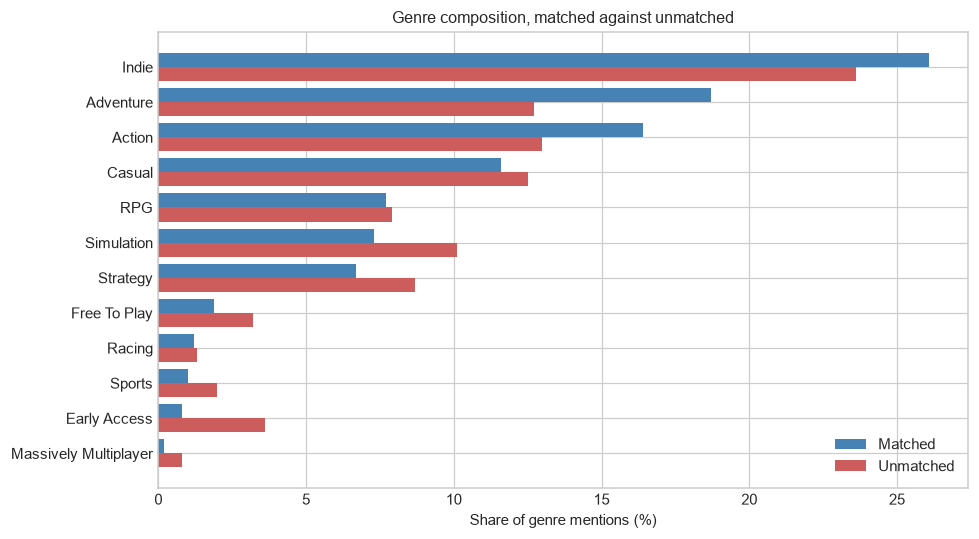

,matched_pct,unmatched_pct,difference
steam_genres,,,
Indie,26.1,23.6,2.5
Adventure,18.7,12.7,6.1
Action,16.4,13.0,3.4
Casual,11.6,12.5,-1.0
RPG,7.7,7.9,-0.2
Simulation,7.3,10.1,-2.8
Strategy,6.7,8.7,-2.0
Free To Play,1.9,3.2,-1.4
Racing,1.2,1.3,-0.1


In [27]:
def genre_share(frame):
    tok = frame["steam_genres"].fillna("").str.split(",").explode().str.strip()
    return tok[tok.ne("")].value_counts(normalize=True) * 100

shares = pd.DataFrame({"matched_pct": genre_share(a), "unmatched_pct": genre_share(b)}).fillna(0)
shares["difference"] = (shares["matched_pct"] - shares["unmatched_pct"]).round(1)
top = shares.nlargest(12, "matched_pct").round(1)

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(top))
ax.barh(y - 0.2, top["matched_pct"], height=0.4, label="Matched", color="steelblue")
ax.barh(y + 0.2, top["unmatched_pct"], height=0.4, label="Unmatched", color="indianred")
ax.set_yticks(y); ax.set_yticklabels(top.index); ax.invert_yaxis()
ax.set_xlabel("Share of genre mentions (%)")
ax.set_title("Genre composition, matched against unmatched")
ax.legend()
plt.tight_layout()
save_fig(fig, "01_q5_genre_composition")
plt.show()
top

### Interpretation: Merge bias and representativeness
**Author**: [Insert Name]  
<!-- Judge whether the matched set is a representative sample of Steam games, and if not, in which direction it is skewed. Cover what the funnel costs at each step, what the match-rate gradient across review buckets implies, which variables show a meaningful standardised difference and what that does to any completion finding, and how you will state this limitation in the report. -->


## 6. How does game age affect reception?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: two versions of the same curve. The unweighted mean treats every game equally, and the pooled rate is total positives over total reviews, which weights by how many reviews each game has. Both carry 95% error bars, and cohorts with fewer than 30 games are dropped. The review-count series is shown on a raw axis and then a log axis.

In [28]:
# Reception against game age, with standard errors.
# SE of a mean is sd / sqrt(n). The pooled rate is total positives over total
# reviews, which weights each game by how many reviews it has.
rated = df[df["steam_review_count"] > 0]
age = rated.groupby("steam_years_since_release").agg(
    games=("steam_appid", "size"),
    mean_rate=("steam_positive_rate", "mean"),
    sd_rate=("steam_positive_rate", "std"),
    total_pos=("steam_positive", "sum"),
    total_rev=("steam_review_count", "sum"),
    median_reviews=("steam_review_count", "median"),
)
age["se_rate"] = age["sd_rate"] / np.sqrt(age["games"])
age["pooled_rate"] = age["total_pos"] / age["total_rev"]
age["pooled_se"] = np.sqrt(age["pooled_rate"] * (1 - age["pooled_rate"]) / age["total_rev"])
age = age[age["games"] >= 30]
age[["games", "mean_rate", "se_rate", "pooled_rate", "pooled_se", "median_reviews"]].round(4)

,games,mean_rate,se_rate,pooled_rate,pooled_se,median_reviews
steam_years_since_release,,,,,,
1,4551,0.8395,0.0034,0.8521,0.0002,12.0
2,9573,0.8095,0.0025,0.8574,0.0001,13.0
3,7482,0.7802,0.0029,0.8426,0.0001,14.0
4,6659,0.7718,0.0029,0.7988,0.0002,17.0
5,6632,0.7602,0.0029,0.8528,0.0001,18.0
6,6234,0.7575,0.0029,0.8605,0.0001,23.0
7,5209,0.7342,0.0033,0.8766,0.0001,24.0
8,5653,0.7018,0.0031,0.8853,0.0001,29.0
9,4605,0.7008,0.0033,0.8587,0.0001,42.0


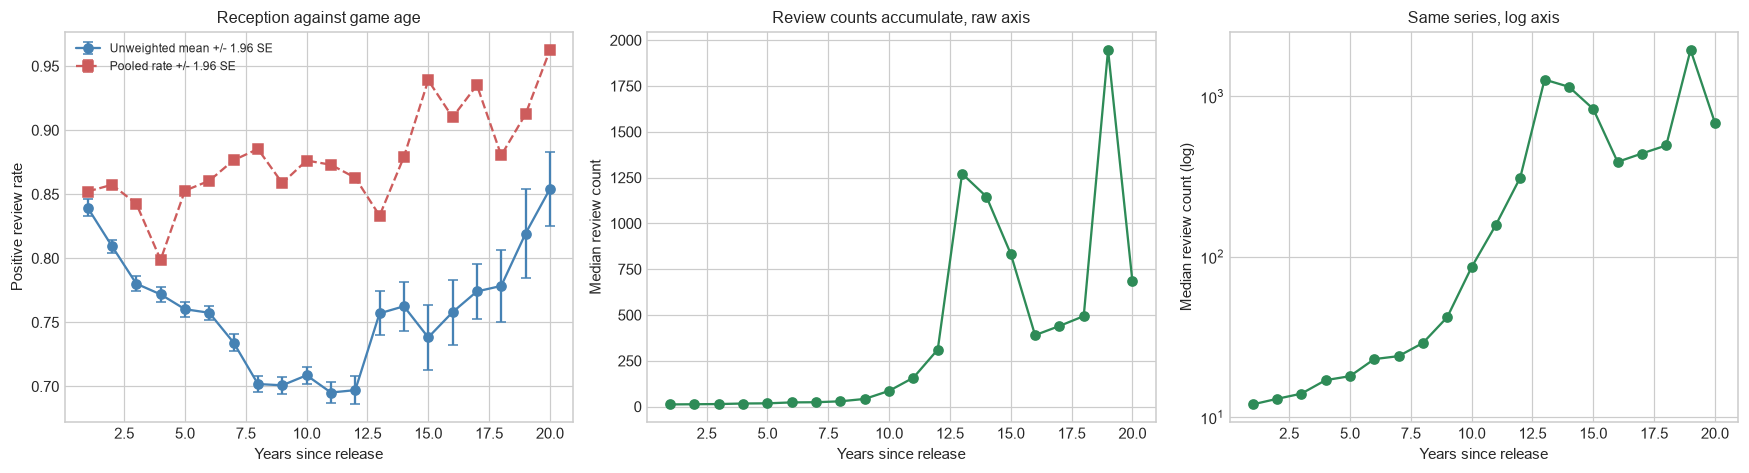

Error bars are narrow where a cohort has many games, so overlapping bars
matter more than the shape of the line.


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

axes[0].errorbar(age.index, age["mean_rate"], yerr=1.96 * age["se_rate"], fmt="o-",
                 capsize=3, color="steelblue", label="Unweighted mean +/- 1.96 SE")
axes[0].errorbar(age.index, age["pooled_rate"], yerr=1.96 * age["pooled_se"], fmt="s--",
                 capsize=3, color="indianred", label="Pooled rate +/- 1.96 SE")
axes[0].set_xlabel("Years since release"); axes[0].set_ylabel("Positive review rate")
axes[0].set_title("Reception against game age")
axes[0].legend(fontsize=8)

axes[1].plot(age.index, age["median_reviews"], marker="o", color="seagreen")
axes[1].set_xlabel("Years since release"); axes[1].set_ylabel("Median review count")
axes[1].set_title("Review counts accumulate, raw axis")

axes[2].plot(age.index, age["median_reviews"], marker="o", color="seagreen")
axes[2].set_yscale("log")
axes[2].set_xlabel("Years since release"); axes[2].set_ylabel("Median review count (log)")
axes[2].set_title("Same series, log axis")

plt.tight_layout()
save_fig(fig, "01_q6_age_and_reception")
plt.show()
print("Error bars are narrow where a cohort has many games, so overlapping bars")
print("matter more than the shape of the line.")

### Interpretation: Game age and reception
**Author**: [Insert Name]  
<!-- Interpret the two curves and their error bars. Cover whether reception genuinely varies with age or whether the differences sit inside the error bars, why the unweighted and pooled curves may diverge, how much of any age pattern could be survivorship among older games rather than a real effect, and whether age needs to be controlled for in later models. -->


## 7. How do the variables correlate?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: Spearman rather than Pearson, since these variables are skewed and the relationships are not expected to be linear. Spearman works on ranks, so it is unaffected by whether a variable is logged. Shown on the full training set and on matched games only, since the completion ratio exists only in the latter.

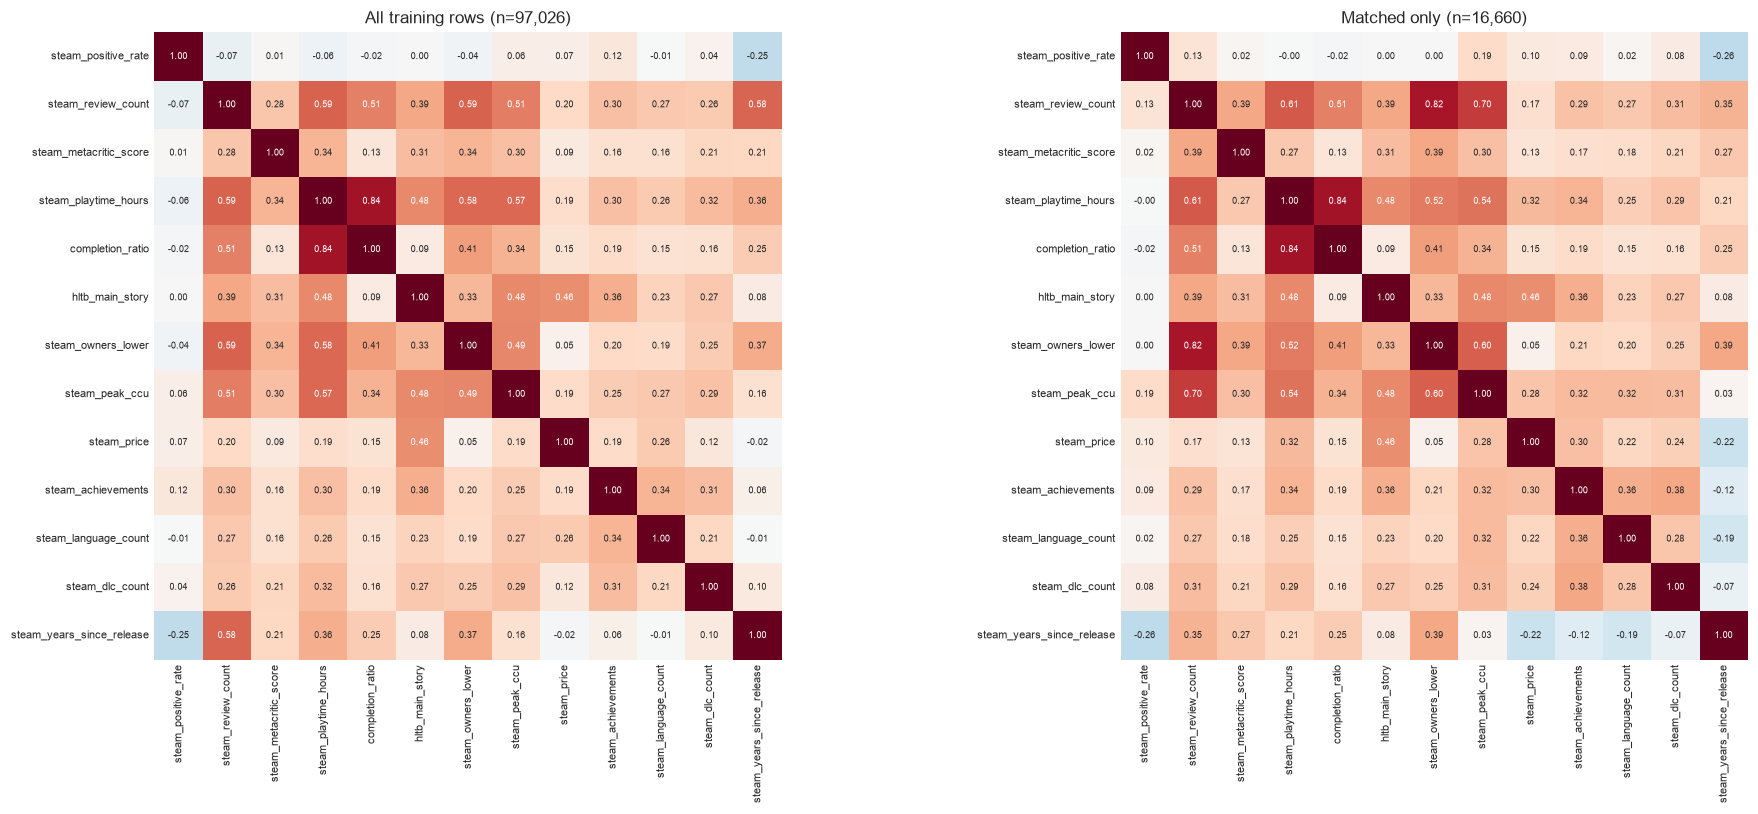

In [30]:
# Spearman rather than Pearson: these variables are skewed and the
# relationships are not expected to be linear.
num = ["steam_positive_rate", "steam_review_count", "steam_metacritic_score", "steam_playtime_hours",
       "completion_ratio", "hltb_main_story", "steam_owners_lower", "steam_peak_ccu", "steam_price",
       "steam_achievements", "steam_language_count", "steam_dlc_count", "steam_years_since_release"]

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (frame, label) in zip(axes, [(df, f"All training rows (n={len(df):,})"),
                                     (matched, f"Matched only (n={len(matched):,})")]):
    corr = frame[num].corr(method="spearman")
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                square=True, cbar=False, annot_kws={"size": 6}, ax=ax)
    ax.set_title(label, fontsize=11)
    ax.tick_params(labelsize=7)
plt.tight_layout()
save_fig(fig, "01_q7_spearman_correlation")
plt.show()

In [31]:
targets = ["steam_positive_rate", "steam_review_count", "steam_metacritic_score",
           "steam_playtime_hours", "completion_ratio", "steam_owners_lower"]
print("Spearman correlation among candidate targets, matched games only:")
print(matched[targets].corr(method="spearman").round(3).to_string())

Spearman correlation among candidate targets, matched games only:
                        steam_positive_rate  steam_review_count  steam_metacritic_score  steam_playtime_hours  completion_ratio  steam_owners_lower
steam_positive_rate                   1.000               0.134                   0.023                -0.003            -0.022               0.004
steam_review_count                    0.134               1.000                   0.390                 0.611             0.507               0.821
steam_metacritic_score                0.023               0.390                   1.000                 0.266             0.133               0.385
steam_playtime_hours                 -0.003               0.611                   0.266                 1.000             0.843               0.518
completion_ratio                     -0.022               0.507                   0.133                 0.843             1.000               0.415
steam_owners_lower                    0.004   

### Interpretation: Correlation structure
**Author**: [Insert Name]  
<!-- Interpret the correlation structure. Cover which predictors move together closely enough to cause collinearity in a regression, how strongly the candidate targets agree with one another, whether the completion ratio carries information the review-based measures do not, and which relationships are strong enough to be worth modelling. -->


## 8. Suggested: how much evidence sits behind each estimate?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this section is not in the agreed list. It is included because the choice of target in AQ1 depends on how reliably each candidate is measured, not only on how it is distributed. Delete it if it is not wanted. The Wilson interval is used rather than the normal approximation, which misbehaves for proportions near 0 and 1 and at small sample sizes.

In [32]:
z = 1.96
rated = df[df["steam_review_count"] > 0].copy()
n, p = rated["steam_review_count"], rated["steam_positive_rate"]
half = (z / (1 + z**2 / n)) * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
rated["wilson_width"] = 2 * half

by_bucket = rated.groupby("steam_review_bucket", observed=True).agg(
    games=("steam_appid", "size"),
    median_reviews=("steam_review_count", "median"),
    mean_positive_rate=("steam_positive_rate", "mean"),
    median_ci_width=("wilson_width", "median"),
)
print("Precision of the positive rate by review count:")
print(by_bucket.round(3).to_string())

print("\nEvidence behind the HowLongToBeat main-story time:")
print(matched["hltb_main_story_polled"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_string())
print(f"matched games whose hltb_main_story rests on fewer than 5 reports: "
      f"{(matched['hltb_main_story_polled'] < 5).sum():,} "
      f"({(matched['hltb_main_story_polled'] < 5).mean() * 100:.1f}%)")

Precision of the positive rate by review count:
                     games  median_reviews  mean_positive_rate  median_ci_width
steam_review_bucket                                                            
1-10                 21414             4.0               0.731            0.603
11-50                19337            22.0               0.758            0.299
51-200               10723            94.0               0.760            0.152
201-1k                7443           395.0               0.786            0.071
1k-5k                 3522          1946.0               0.821            0.030
5k-20k                1337          8790.0               0.848            0.013
20k+                   773         45038.0               0.871            0.005

Evidence behind the HowLongToBeat main-story time:
count    16657.0
mean        37.5
std        190.2
min          1.0
10%          1.0
25%          1.0
50%          3.0
75%         12.0
90%         50.0
max       8013.0
matched ga

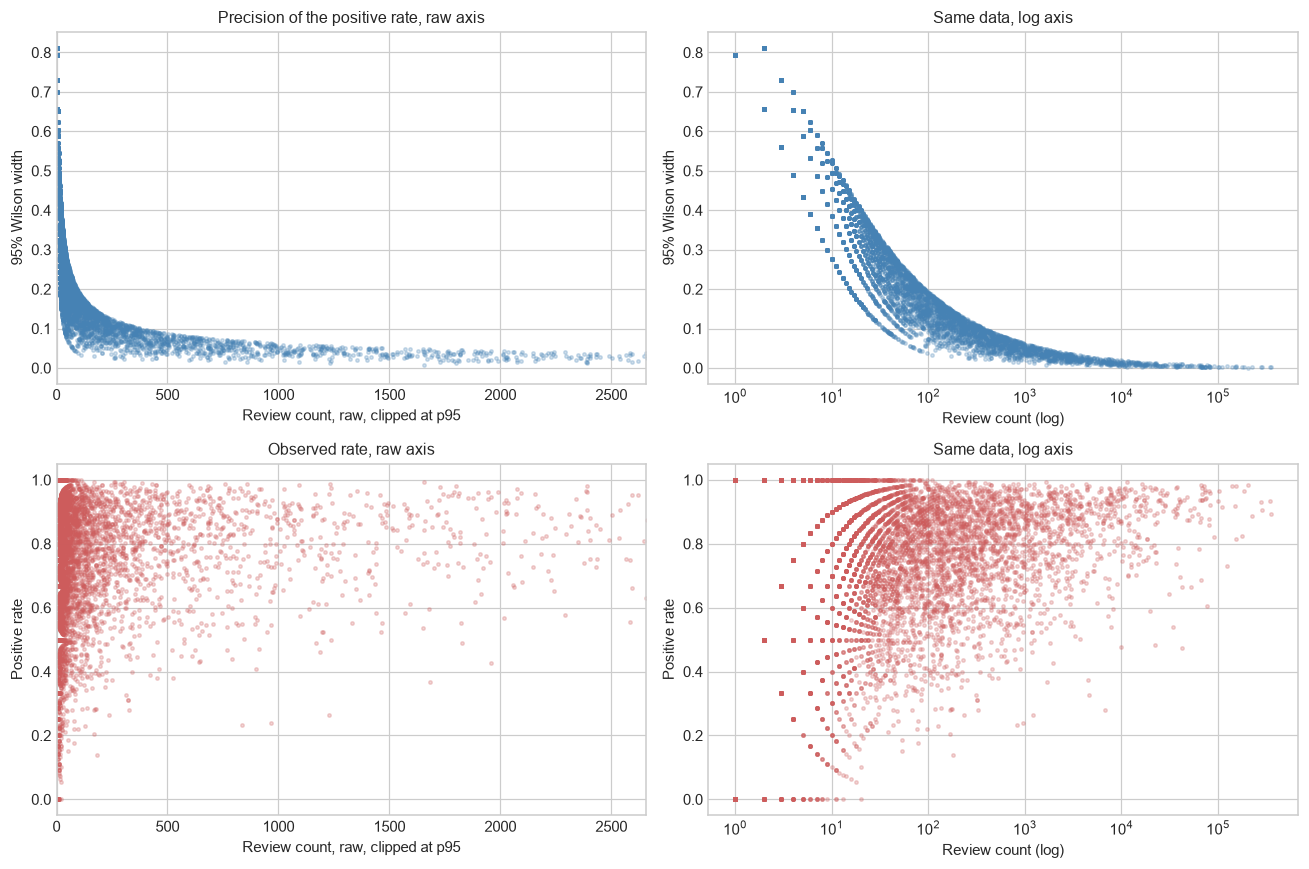

In [33]:
s = rated.sample(min(8000, len(rated)), random_state=config.SEED)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(s["steam_review_count"], s["wilson_width"], s=5, alpha=0.25, color="steelblue")
axes[0, 0].set_xlim(0, s["steam_review_count"].quantile(0.95))
axes[0, 0].set_xlabel("Review count, raw, clipped at p95"); axes[0, 0].set_ylabel("95% Wilson width")
axes[0, 0].set_title("Precision of the positive rate, raw axis")

axes[0, 1].scatter(s["steam_review_count"], s["wilson_width"], s=5, alpha=0.25, color="steelblue")
axes[0, 1].set_xscale("log")
axes[0, 1].set_xlabel("Review count (log)"); axes[0, 1].set_ylabel("95% Wilson width")
axes[0, 1].set_title("Same data, log axis")

axes[1, 0].scatter(s["steam_review_count"], s["steam_positive_rate"], s=5, alpha=0.25, color="indianred")
axes[1, 0].set_xlim(0, s["steam_review_count"].quantile(0.95))
axes[1, 0].set_xlabel("Review count, raw, clipped at p95"); axes[1, 0].set_ylabel("Positive rate")
axes[1, 0].set_title("Observed rate, raw axis")

axes[1, 1].scatter(s["steam_review_count"], s["steam_positive_rate"], s=5, alpha=0.25, color="indianred")
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlabel("Review count (log)"); axes[1, 1].set_ylabel("Positive rate")
axes[1, 1].set_title("Same data, log axis")

plt.tight_layout()
save_fig(fig, "01_q8_evidence_raw_vs_log")
plt.show()

### Interpretation: Evidence behind the estimates
**Author**: [Insert Name]  
<!-- Interpret how much the precision of each measure varies across games. Cover how wide the interval on the positive rate is for a game at the low end against the high end, how many games rest on very few HowLongToBeat reports, and whether the right response is a minimum-evidence threshold, partial pooling, or carrying the uncertainty through the model. -->


## Save for stage 02
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this stage adds derived columns and filters no rows, so the count out matches the count in. The cleaning decisions raised above belong to stage 02.

In [34]:
df.to_parquet(config.INTERIM / "01_eda.parquet", index=False)
print(f"rows in : {len(train):,}")
print(f"rows out: {len(df):,}  (no rows filtered in this stage)")
print(f"columns : {train.shape[1]} in, {df.shape[1]} out")
print(f"figures : {len(list(config.FIGURES.glob('01_*.png')))} written to outputs/figures")

rows in : 97,026
rows out: 97,026  (no rows filtered in this stage)
columns : 72 in, 83 out
figures : 13 written to outputs/figures
